# Module Assignment — Exploratory Data Analysis on Hotel Bookings

## Case Study: Hotel Bookings

In this assignment you'll apply everything from this module to a **large, genuinely messy** real-world dataset: **119,390 hotel bookings with 32 columns**.

You will practise the full EDA workflow:

1. **Exploring / diagnosing** the data
2. **Cleaning** — missing values, duplicates, wrong data types, invalid values
3. **Visualizing** with matplotlib
4. **Manipulating** — sorting, filtering, new columns, `groupby`, `pivot_table`, `crosstab`
5. **Drawing conclusions**

**This dataset is deliberately challenging** — it has 4 columns with missing data (one is ~94% empty!), ~32,000 duplicate rows, dates stored as text, and some physically impossible values. Read each prompt carefully and think about *why* a step is needed, not just *how*.

### Instructions

- Write your **full code** in the empty cell below each exercise
- Some exercises ask a question in **markdown** — answer it in a comment or a short written note.
- Work through the notebook **in order**: later sections rely on the cleaned DataFrame from earlier ones.
- Worked answers are in **`Module_Assignment_Hotel_Bookings_Solutions.ipynb`** — try hard before peeking.

### Key columns

| Column | Meaning |
|---|---|
| `hotel` | Resort Hotel or City Hotel |
| `is_canceled` | 1 = booking was cancelled, 0 = not |
| `lead_time` | Days between booking and arrival |
| `arrival_date_month` | Month of arrival (text, e.g. "July") |
| `adults` / `children` / `babies` | Number of guests of each type |
| `meal`, `country`, `market_segment`, `customer_type` | Categorical descriptors |
| `adr` | Average Daily Rate (price per night) |
| `agent` / `company` | IDs of the booking agent / company (lots of missing) |
| `reservation_status_date` | Date of the last status change (text) |

## Import Libraries

**Exercise 0.** Import the required libraries.

In [1]:
import pandas as pd


In [2]:
import matplotlib
import matplotlib.pyplot as plt 

## Load Dataset

**Exercise 1.** Read `hotel_bookings.csv` into a DataFrame called `df` and display the first 5 rows.

In [3]:
df = pd.read_csv('../Assignment/hotel_bookings.csv')
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


# 1. Exploring / Diagnosing the Data

**Exercise 2.** Report the dataset's **shape** (rows, columns). Then  inspect column names, non-null counts, and dtypes.

In [ ]:
df.shape 

(119390, 32)

In [26]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

**Exercise 3.** Show the summary statistics for the **numeric** columns `. Look at the `adr` column — what is suspicious about its **minimum** value?

In [6]:
df.describe() #for numeric columns 


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [ ]:
df['adr'].min() # min value is a negstive vslue while 'adr' column represents price per night 

np.float64(-6.38)

**Exercise 4.** Build a table showing, **for every column**, the number of missing values **and** the percentage missing — sorted from most to least missing. Which columns are the worst?

In [8]:
df.isnull().sum().sort_values(ascending = False)

company                           112593
agent                              16340
country                              488
children                               4
arrival_date_month                     0
arrival_date_week_number               0
hotel                                  0
is_canceled                            0
stays_in_weekend_nights                0
arrival_date_day_of_month              0
adults                                 0
stays_in_week_nights                   0
babies                                 0
meal                                   0
lead_time                              0
arrival_date_year                      0
distribution_channel                   0
market_segment                         0
previous_bookings_not_canceled         0
is_repeated_guest                      0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
previous_cancellations                 0
deposit_type    

In [ ]:
# the worst column is "company "

**Exercise 5.** For the categorical columns `hotel`, `meal`, `customer_type` and `market_segment`, print the **count of each unique value**.

In [10]:
cols = df[['hotel', 'meal', 'customer_type', 'market_segment']]
print(cols.dtypes)

hotel             str
meal              str
customer_type     str
market_segment    str
dtype: object


In [12]:
for col in cols : 
    # print(f"\n{col}:") # print the name of the column
    print(cols[col].value_counts(dropna = False)) # the count of each value

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64
customer_type
Transient          89613
Transient-Party    25124
Contract            4076
Group                577
Name: count, dtype: int64
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64


# 2. Cleaning the Data

Work on a copy so the raw data stays intact: start this section with `df_clean = df.copy()`.

**Exercise 6.** Make a copy called `df_clean`. Then handle the missing values:

- `children` → fill missing with `0`
- `country` → fill missing with `"Unknown"`
- `company` and `agent` are mostly empty → **drop both columns**

Confirm there are no missing values left.

In [60]:
df_clean = df.copy()
df_clean.head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,2015-07-03
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,No Deposit,303.0,NaN,0,Transient,103.0,0,1,Check-Out,2015-07-03
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,...,No Deposit,240.0,NaN,0,Transient,82.0,0,1,Canceled,2015-05-06
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,...,No Deposit,15.0,NaN,0,Transient,105.5,0,0,Canceled,2015-04-22


In [73]:
df_clean['children']

0         0.0
1         0.0
2         0.0
3         0.0
4         0.0
         ... 
119385    0.0
119386    0.0
119387    0.0
119388    0.0
119389    0.0
Name: children, Length: 119390, dtype: float64

In [5]:
df_clean['children'].isnull().sum()


np.int64(4)

In [61]:
df_clean['children'] = df_clean['children'].fillna(0.0)
df_clean['children']

0         0.0
1         0.0
2         0.0
3         0.0
4         0.0
         ... 
119385    0.0
119386    0.0
119387    0.0
119388    0.0
119389    0.0
Name: children, Length: 119390, dtype: float64

In [7]:
df_clean['children'].isnull().sum()


np.int64(0)

**Exercise 7.** How many **fully duplicated rows** does `df_clean` contain? Remove them, then confirm the count is now 0 and report the new shape.

In [77]:
df_clean.duplicated().sum()

np.int64(31994)

In [62]:
df_clean = df_clean.drop_duplicates()  #31994 rows

In [9]:
df_clean.duplicated().sum()

np.int64(0)

In [10]:
df_clean.shape  # duplicated are removed

(87396, 32)

**Exercise 8.** Fix the data types:

- Convert `reservation_status_date` from text to a real **datetime**.
- `children` was a float because of the missing values — now convert it to **int**.

Verify with `.dtypes`.

In [11]:
df_clean['reservation_status_date'].dtypes

<StringDtype(storage='python', na_value=nan)>

In [81]:
df_clean['reservation_status_date'] = df_clean['reservation_status_date'].astype('datetime64[us]')
df_clean['reservation_status_date']

0        2015-07-01
1        2015-07-01
2        2015-07-02
3        2015-07-02
4        2015-07-03
            ...    
119385   2017-09-06
119386   2017-09-07
119387   2017-09-07
119388   2017-09-07
119389   2017-09-07
Name: reservation_status_date, Length: 87396, dtype: datetime64[us]

In [63]:
#2nd method
df_clean['reservation_status_date'] = pd.to_datetime(df_clean['reservation_status_date'] )
df_clean['reservation_status_date']

0        2015-07-01
1        2015-07-01
2        2015-07-02
3        2015-07-02
4        2015-07-03
            ...    
119385   2017-09-06
119386   2017-09-07
119387   2017-09-07
119388   2017-09-07
119389   2017-09-07
Name: reservation_status_date, Length: 87396, dtype: datetime64[us]

In [64]:
df_clean['children'] = df_clean['children'].astype(int)

In [14]:
df_clean['children'].dtypes

dtype('int64')

**Exercise 9.** Remove **invalid values**:

- The `adr` (price) cannot be negative — keep only rows where `adr >= 0`.
- A booking with **zero guests** makes no sense. Create a `total_guests = adults + children + babies` column, then drop rows where `total_guests == 0`.

Report how many rows remain.

In [84]:
df_clean.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [65]:
df_clean = df_clean[df_clean['adr'] >= 0]  #return the whole data 
df_clean

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


In [16]:
df_clean['adr'].min() # 0 is the min

np.float64(0.0)

In [17]:
df_clean.shape # one value removed 

(87395, 32)

# 3. Visualizing the Data 

**Exercise 10.** Plot a **histogram** of `lead_time` (use `bins=50`). Add a title and axis labels. What does the shape tell you about how far in advance people book?

[Text(0.5, 1.0, 'Lead Time Frequency'),
 Text(0.5, 0, 'Lead time'),
 Text(0, 0.5, 'Frequency')]

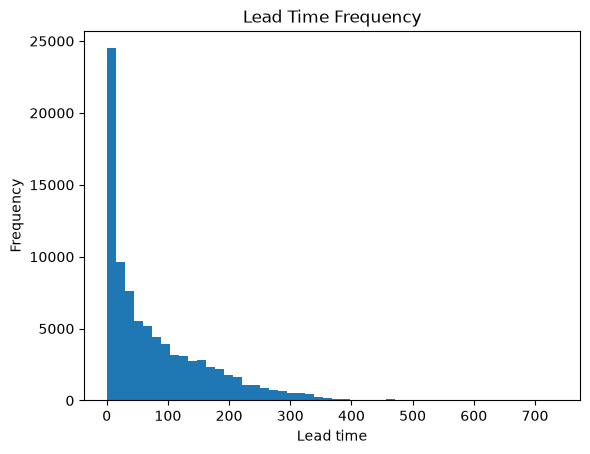

In [18]:
ax = df_clean['lead_time'].plot.hist(bins = 50)
ax.set(title = "Lead Time Frequency", xlabel = 'Lead time', ylabel = 'Frequency')
#Days between booking and arrival, the frequent is when the lead time is so near (in the same day), 
# make the booking in the same day if arrival 


**Exercise 11.** Make a **bar chart** of the number of bookings per `hotel` (Resort vs City). Use `value_counts()` and label the chart.

In [32]:
hotel_counts = df_clean['hotel'].value_counts()
hotel_counts

hotel
City Hotel      53428
Resort Hotel    33967
Name: count, dtype: int64

[Text(0.5, 1.0, 'Number of Bookings per Hotel Type'),
 Text(0.5, 0, 'hotel type'),
 Text(0, 0.5, 'nb of booking')]

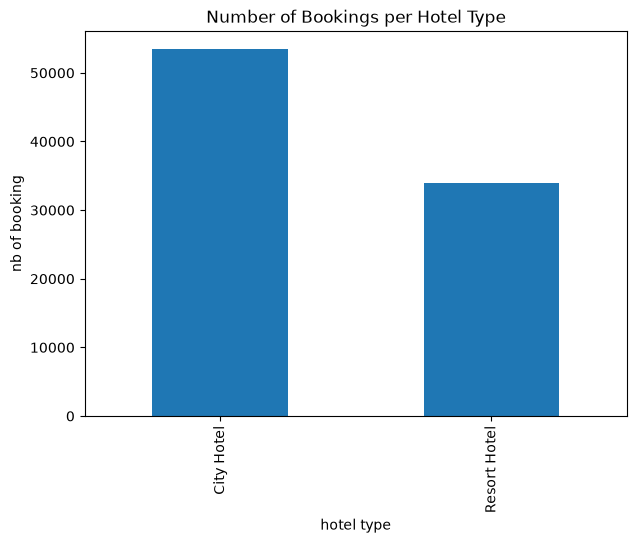

In [35]:
ax1 = hotel_counts.plot(kind='bar', figsize=(7, 5))
ax1.set(title = 'Number of Bookings per Hotel Type', xlabel = 'hotel type', ylabel = 'nb of booking')

**Exercise 12.** Draw a **scatter plot** of `lead_time` (x) vs `adr` (y). Use `alpha` and a small marker size `s` so the dense cloud is readable.

Text(0.5, 1.0, 'Lead time VS adr')

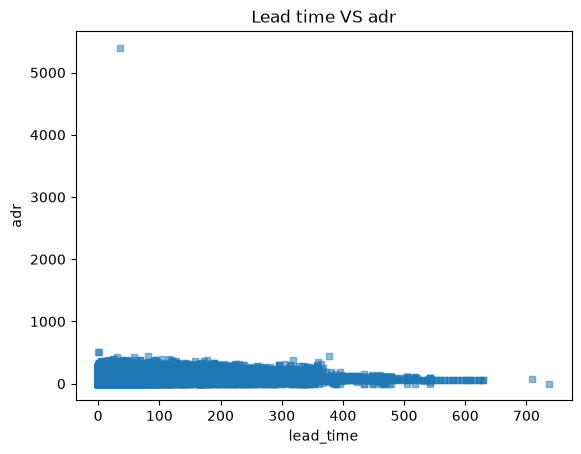

In [49]:
ax2 = df_clean.plot(x = 'lead_time' ,y = 'adr', kind = 'scatter', alpha=0.5, marker = 's')
ax2.set_title("Lead time VS adr")

**Exercise 13.** Build a **2×2 grid of subplots** (`figsize=(12, 9)`):

- histogram of `adr`
- histogram of `total_guests`
- bar chart of `customer_type` counts
- bar chart of `is_canceled` counts (0 vs 1)

Give each subplot a title and call `fig.tight_layout()`.

In [78]:
customer_counts = df_clean['customer_type'].value_counts()
customer_counts

customer_type
Transient          71986
Transient-Party    11726
Contract            3139
Group                544
Name: count, dtype: int64

In [68]:
canceled_counts = df_clean['is_canceled'].value_counts()
canceled_counts

is_canceled
0    63370
1    24025
Name: count, dtype: int64

In [75]:
df_clean['total_guests'] = df_clean['children'] + df_clean['adults'] + df_clean['babies']
df_clean['total_guests'] 

0         2
1         2
2         1
3         1
4         2
         ..
119385    2
119386    3
119387    2
119388    2
119389    2
Name: total_guests, Length: 87395, dtype: int64

Text(0.5, 1.0, 'cancellation status')

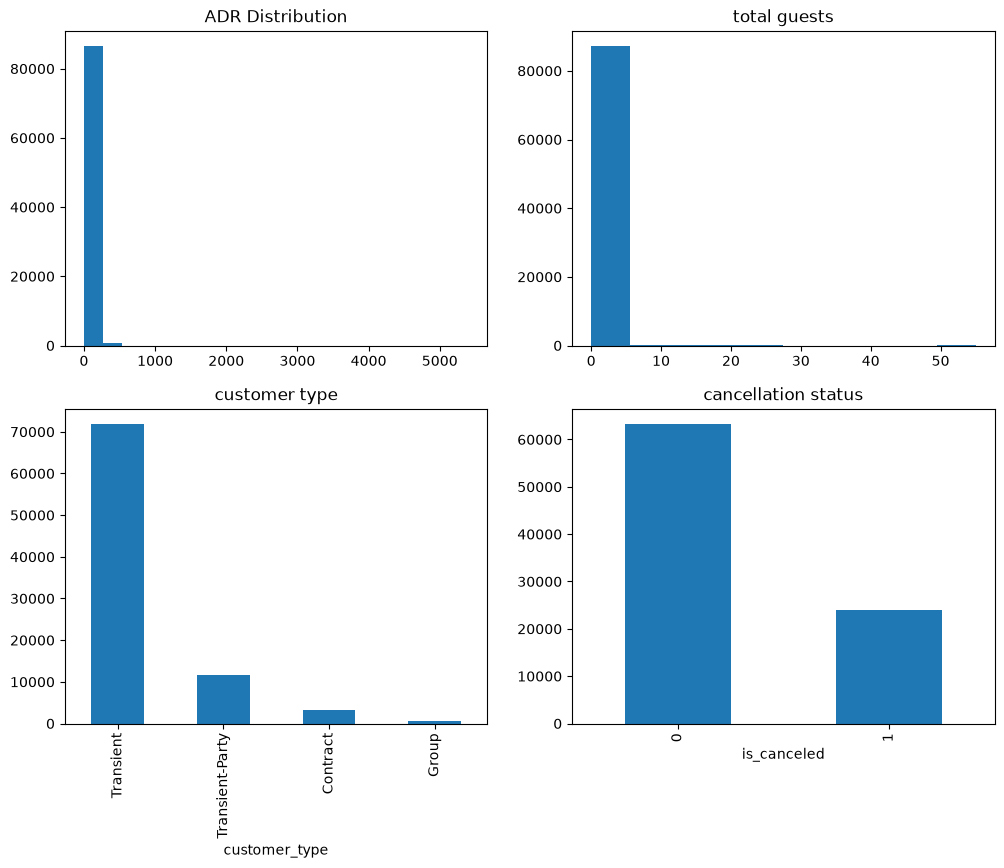

In [87]:
fig, ((ax1, ax2), (ax3, ax4)) =plt.subplots(nrows = 2, ncols = 2, figsize= (12,9))
ax1.hist(df_clean['adr'], bins=20)
ax1.set_title('ADR Distribution')
ax2.hist(df_clean['total_guests'], bins=10)
ax2.set_title('total guests')

customer_counts.plot(kind = 'bar', ax = ax3)
ax3.set_title('customer type')
canceled_counts.plot(kind = 'bar', ax = ax4)
ax4.set_title('cancellation status')


**Exercise 14.** Compute the **correlation matrix** of the numeric columns and display it as a **heatmap** using `ax.imshow(..., cmap="coolwarm")`. Add a colorbar and tick labels with the column names.

*Tip: `df_clean.select_dtypes('number').corr()` gives the matrix; use `ax.set_xticks`/`set_yticks` + `set_xticklabels`/`set_yticklabels` for the labels.*

In [96]:
import numpy as np

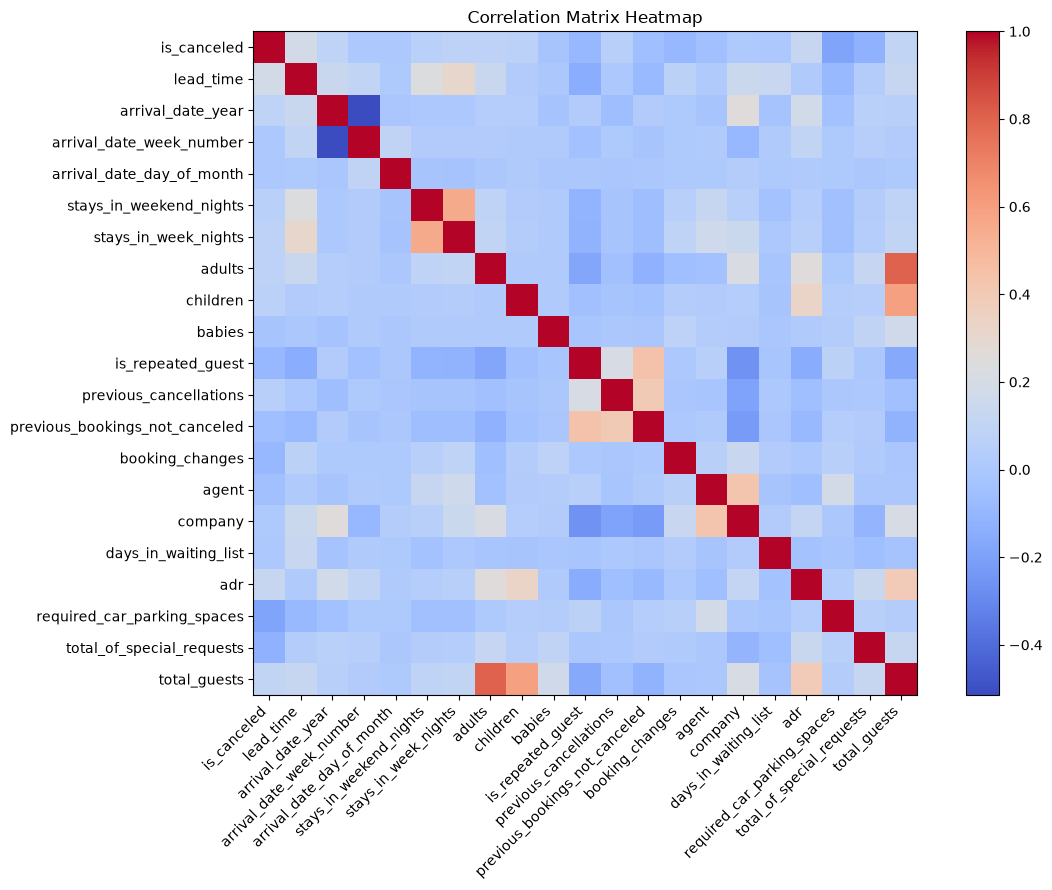

In [99]:
corr_matrix = df_clean.select_dtypes('number').corr()
corr_matrix

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr_matrix, cmap='coolwarm')
fig.colorbar(im, ax=ax)
columns = corr_matrix.columns
ax.set_xticks(np.arange(len(columns)))
ax.set_yticks(np.arange(len(columns)))
ax.set_xticklabels(columns)
ax.set_yticklabels(columns)

plt.setp(ax.get_xticklabels(), rotation=45, ha='right') # to be clear to read
ax.set_title('Correlation Matrix Heatmap')
plt.tight_layout()
plt.show()

# 4. Manipulating the Data

**Exercise 15.** **Sort** `df_clean` by `adr` in descending order and show the **top 10** most expensive bookings (columns `hotel`, `arrival_date_month`, `adr`).

In [103]:
df_clean = df_clean.sort_values('adr', ascending = False)
df_clean

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guests
48515,City Hotel,1,35,2016,March,13,25,0,1,2,...,12.0,NaN,0,Transient,5400.0,0,0,Canceled,2016-02-19,2
111403,City Hotel,0,0,2017,May,19,9,0,1,1,...,159.0,NaN,0,Transient,510.0,0,0,Check-Out,2017-05-10,1
15083,Resort Hotel,0,1,2015,July,29,15,0,1,2,...,NaN,NaN,0,Transient,508.0,1,0,Check-Out,2015-07-16,2
103912,City Hotel,0,81,2016,December,53,31,1,1,2,...,NaN,NaN,0,Transient-Party,451.5,0,4,Check-Out,2017-01-02,4
13142,Resort Hotel,1,378,2017,August,31,1,4,10,2,...,314.0,NaN,0,Transient,450.0,0,0,Canceled,2016-07-22,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38759,Resort Hotel,0,149,2017,July,30,25,8,21,2,...,240.0,NaN,0,Transient,0.0,0,0,Check-Out,2017-08-23,2
106638,City Hotel,0,2,2017,February,9,28,0,0,2,...,NaN,NaN,0,Transient,0.0,1,0,Check-Out,2017-02-28,2
22523,Resort Hotel,0,25,2016,March,14,30,0,0,1,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2016-03-30,1
38776,Resort Hotel,0,0,2017,July,30,29,0,0,2,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2017-07-29,2


In [111]:
df_clean[['hotel', 'arrival_date_month', 'adr']].head(10)

,hotel,arrival_date_month,adr
48515,City Hotel,March,5400.00
111403,City Hotel,May,510.00
15083,Resort Hotel,July,508.00
103912,City Hotel,December,451.50
13142,Resort Hotel,August,450.00
13391,Resort Hotel,August,437.00
39155,Resort Hotel,August,426.25
39568,Resort Hotel,August,402.00
39118,Resort Hotel,July,397.38
39517,Resort Hotel,August,392.00


**Exercise 16.** Use boolean filtering to select **City Hotel bookings that were cancelled** (`hotel == "City Hotel"` **and** `is_canceled == 1`). How many are there?

In [121]:
df_clean[(df_clean['hotel'] == "City Hotel") & (df_clean['is_canceled'] == 1)]


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guests
48515,City Hotel,1,35,2016,March,13,25,0,1,2,...,12.0,NaN,0,Transient,5400.00,0,0,Canceled,2016-02-19,2
72966,City Hotel,1,31,2017,August,32,11,0,1,2,...,8.0,NaN,0,Transient,352.50,0,1,Canceled,2017-07-12,5
67983,City Hotel,1,23,2017,May,19,10,2,4,2,...,9.0,NaN,0,Transient,328.67,0,3,No-Show,2017-05-10,4
68097,City Hotel,1,38,2017,May,19,12,2,7,3,...,7.0,NaN,0,Transient,321.94,0,1,Canceled,2017-04-04,4
73335,City Hotel,1,0,2017,August,33,19,0,1,2,...,NaN,NaN,0,Group,318.00,0,0,Canceled,2017-08-19,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68178,City Hotel,1,4,2017,May,20,15,1,0,1,...,NaN,NaN,0,Transient,0.00,0,0,Canceled,2017-05-12,1
55424,City Hotel,1,14,2016,August,33,13,1,1,0,...,7.0,NaN,0,Transient,0.00,0,1,Canceled,2016-07-30,2
42436,City Hotel,1,3,2015,September,36,5,2,2,1,...,1.0,NaN,0,Transient-Party,0.00,0,0,Canceled,2015-09-03,1
46856,City Hotel,1,0,2016,January,4,22,0,0,1,...,NaN,NaN,0,Transient,0.00,0,0,Canceled,2016-01-22,1


In [122]:
df_clean.shape[0]

87395

**Exercise 17.** Group by `hotel` and compute the **mean `adr`** and the **cancellation rate** (mean of `is_canceled`) for each hotel. Which hotel cancels more?

In [ ]:
df_clean.groupby(['hotel'])[['adr', 'is_canceled']].mean()
# city hotel cancels more

,adr,is_canceled
hotel,,
City Hotel,110.985944,0.300386
Resort Hotel,99.028449,0.234816


**Exercise 18.** Produce a **grouped summary**: group by **both** `hotel` and `customer_type`, and aggregate `adr` with **mean, median and count** in one call.

In [134]:
df_clean.groupby(['hotel', 'customer_type'])['adr'].agg(['mean', 'median', 'count'])

mean  median  count
hotel        customer_type                             
City Hotel   Contract         107.561149  103.50   1471
             Group             93.325793   85.00    271
             Transient        114.023751  108.00  44641
             Transient-Party   93.131163   90.00   7045
Resort Hotel Contract          79.693843   72.95   1668
             Group             75.463773   61.60    273
             Transient        103.788835   84.01  27345
             Transient-Party   79.483598   66.00   4681

**Exercise 19.** Build a **`crosstab`** of `hotel` (rows) vs `is_canceled` (columns) to count bookings in each combination.

In [137]:
pd.crosstab(df_clean['hotel'], df_clean['is_canceled'])


is_canceled,0,1
hotel,,
City Hotel,37379,16049
Resort Hotel,25991,7976


**Exercise 20.** Build a **`pivot_table`** with `hotel` as the index, `is_canceled` as the columns, and the **mean `adr`** as the values. Do cancelled bookings have a different average price?

In [141]:
pd.pivot_table(data = df_clean,
                index ='hotel',
                columns = 'is_canceled',
                values = 'adr',
                aggfunc='mean',
            )
# canceled bookings have ~ equal average price btw 2 types of hotel

is_canceled,0,1
hotel,,
City Hotel,108.284982,117.276632
Resort Hotel,92.970192,118.770194


# 5. Putting It Together

**Exercise 21.** Compute the **cancellation rate per arrival month** and plot it as a bar chart, with the months in **calendar order** (January → December), not alphabetical.

*Tip: group by `arrival_date_month`, take the mean of `is_canceled`, then `.reindex(...)` with a list of month names in order.*

In [145]:
df_clean1 = df_clean.groupby('arrival_date_month')['is_canceled'].mean()
df_clean1

arrival_date_month
April        0.304628
August       0.321844
December     0.268564
February     0.232043
January      0.221180
July         0.317987
June         0.303155
March        0.243610
May          0.292280
November     0.211011
October      0.236804
September    0.245441
Name: is_canceled, dtype: float64

In [149]:
months = ['January', 'February', 'March', 'April', 'May', 'June',
            'July', 'August', 'September', 'October', 'November', 'December']
df_clean1.reindex(months)

arrival_date_month
January      0.221180
February     0.232043
March        0.243610
April        0.304628
May          0.292280
June         0.303155
July         0.317987
August       0.321844
September    0.245441
October      0.236804
November     0.211011
December     0.268564
Name: is_canceled, dtype: float64

## 🏆 Challenge Exercises

These are open-ended — combine the skills above and explain what you find in a short comment.

1. **Total nights & revenue:** create `total_nights = stays_in_weekend_nights + stays_in_week_nights`, then estimate revenue as `adr * total_nights`. Which `market_segment` brings the most total estimated revenue? (Remember: cancelled bookings earn nothing — decide how to handle them and justify it.)
2. **Lead time vs cancellation:** bin `lead_time` into buckets (e.g. `pd.cut` at 0, 30, 90, 180, 365, ∞) and show the cancellation rate per bucket. Do bookings made far in advance get cancelled more?
3. **Repeat guests:** compare the cancellation rate of repeated guests (`is_repeated_guest == 1`) vs new guests. Visualize the difference.
4. **Your own question:** pose one question about the data, answer it with code + a plot, and write a one-line conclusion.

In [ ]:
#1
df_clean['total_nights'] = df_clean['stays_in_weekend_nights'] + df_clean['stays_in_week_nights']
df_clean['estimate_revenue'] = df_clean['adr'] * df_clean['total_nights']
df_clean['estimate_revenue']



48515     5400.0
111403     510.0
15083      508.0
103912     903.0
13142     6300.0
           ...  
38759        0.0
106638       0.0
22523        0.0
38776        0.0
21671        0.0
Name: estimate_revenue, Length: 87395, dtype: float64

In [159]:
df_clean2= df_clean[df_clean['is_canceled'] == 0]
df_clean2

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guests,total_nights,estimate_revenue
111403,City Hotel,0,0,2017,May,19,9,0,1,1,...,0,Transient,510.00,0,0,Check-Out,2017-05-10,1,1,510.0
15083,Resort Hotel,0,1,2015,July,29,15,0,1,2,...,0,Transient,508.00,1,0,Check-Out,2015-07-16,2,1,508.0
103912,City Hotel,0,81,2016,December,53,31,1,1,2,...,0,Transient-Party,451.50,0,4,Check-Out,2017-01-02,4,2,903.0
39155,Resort Hotel,0,31,2017,August,31,1,2,6,2,...,0,Transient,426.25,0,2,Check-Out,2017-08-09,4,8,3410.0
39568,Resort Hotel,0,104,2017,August,33,17,2,3,3,...,0,Transient,402.00,0,1,Check-Out,2017-08-22,4,5,2010.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38759,Resort Hotel,0,149,2017,July,30,25,8,21,2,...,0,Transient,0.00,0,0,Check-Out,2017-08-23,2,29,0.0
106638,City Hotel,0,2,2017,February,9,28,0,0,2,...,0,Transient,0.00,1,0,Check-Out,2017-02-28,2,0,0.0
22523,Resort Hotel,0,25,2016,March,14,30,0,0,1,...,0,Transient,0.00,0,0,Check-Out,2016-03-30,1,0,0.0
38776,Resort Hotel,0,0,2017,July,30,29,0,0,2,...,0,Transient,0.00,0,0,Check-Out,2017-07-29,2,0,0.0


In [160]:
df_clean2['market_segment']

111403    Offline TA/TO
15083         Corporate
103912           Direct
39155            Direct
39568         Online TA
              ...      
38759         Online TA
106638           Direct
22523            Direct
38776            Direct
21671            Direct
Name: market_segment, Length: 63370, dtype: str

In [ ]:
df_clean2[['market_segment', 'estimate_revenue']].max()  #online TA  with a revenue of 7590

market_segment      Online TA
estimate_revenue       7590.0
dtype: object

In [166]:
#2 
df_clean['lead_time']

48515      35
111403      0
15083       1
103912     81
13142     378
         ... 
38759     149
106638      2
22523      25
38776       0
21671     164
Name: lead_time, Length: 87395, dtype: int64

In [ ]:
bins = [0, 30, 90, 180, 365, float('inf')]

labels = ['0-30 days', '31-90 days', '91-180 days',
        '181-365 days', '365+ days']

df_clean['lead_time_bk'] = pd.cut(  #create lead time buckets(group)
    df_clean['lead_time'],
    bins=bins,
    labels=labels,
    include_lowest = True
)
df_clean['lead_time_bk']

48515      31-90 days
111403      0-30 days
15083       0-30 days
103912     31-90 days
13142       365+ days
             ...     
38759     91-180 days
106638      0-30 days
22523       0-30 days
38776       0-30 days
21671     91-180 days
Name: lead_time_bk, Length: 87395, dtype: category
Categories (5, str): ['0-30 days' < '31-90 days' < '91-180 days' < '181-365 days' < '365+ days']

In [203]:
#3
cancellation_rate = df_clean.groupby(['lead_time_bk'])['is_canceled'].mean() *100
cancellation_rate

lead_time_bk
0-30 days       16.418427
31-90 days      32.008442
91-180 days     34.983281
181-365 days    39.682114
365+ days       40.884956
Name: is_canceled, dtype: float64

(array([0, 1, 2, 3, 4]),
 [Text(0, 0, '0-30 days'),
  Text(1, 0, '31-90 days'),
  Text(2, 0, '91-180 days'),
  Text(3, 0, '181-365 days'),
  Text(4, 0, '365+ days')])

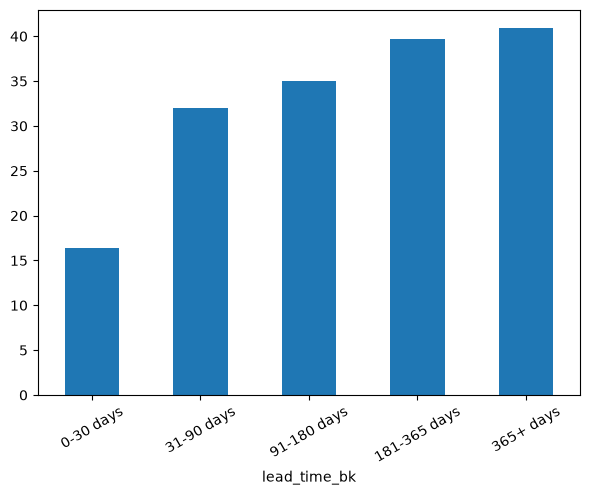

In [205]:
cancellation_rate.plot(
    kind = 'bar', 
    figsize=(7, 5)
)
plt.xticks(rotation=30)

In [199]:
# compare the cancellation rate of repeated guests (is_repeated_guest == 1) vs new guests.
cancellation_rate_guest = df_clean.groupby(['is_repeated_guest'])['is_canceled'].mean() *100
cancellation_rate_guest

is_repeated_guest
0    28.296877
1     7.644991
Name: is_canceled, dtype: float64

In [ ]:
# cancellation rate by a new guest is more than cancellation rate with an old guest.

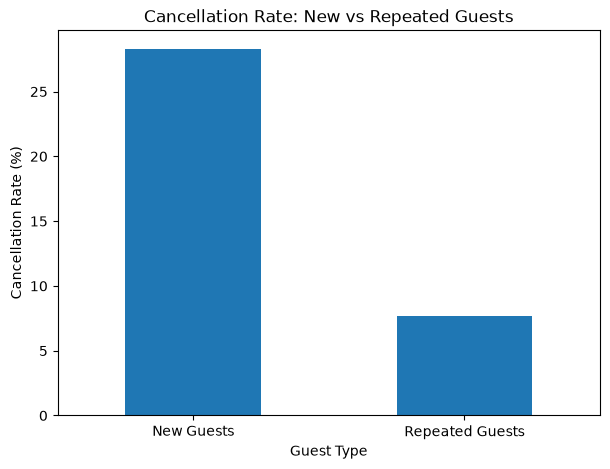

In [201]:
cancellation_rate_guest.plot(
    kind='bar',
    figsize=(7, 5),
    
)
plt.title('Cancellation Rate: New vs Repeated Guests')
plt.xlabel('Guest Type')
plt.ylabel('Cancellation Rate (%)')
plt.xticks([0, 1], ['New Guests', 'Repeated Guests'], rotation=0) #  to changr the name of columns
plt.show()


In [ ]:
#my own question
# Compare the cancellation rate differ between City Hotels and Resort Hotels.
cancellation_rate_hotel = df_clean.groupby(['hotel'])['is_canceled'].mean()*100
cancellation_rate_hotel

# the city hotel has a higher cancellation than resort hotel. 


hotel
City Hotel      30.038557
Resort Hotel    23.481615
Name: is_canceled, dtype: float64

## Conclusion

In a short markdown note below, summarise **3 things you learned** about hotel bookings from this analysis (e.g. which hotel cancels more, when cancellations peak, what drives price).

*Write your conclusions here...*

3 things i learned : 
- cancellation rate changes according different factors (the city hotel has a higher cancellation than resort hotel, maybe we should study the time btw booking and arrival in each hotel type to estimate or better understand possible reasons of cancelling)
- bookings before a lomg time lead to a higher cancellation rate, while booking in the same day or few days before are less canceled.
- usually new guest cancels booking more than an old guest  (repeated guest, that become as a loyal customer or guest)